In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

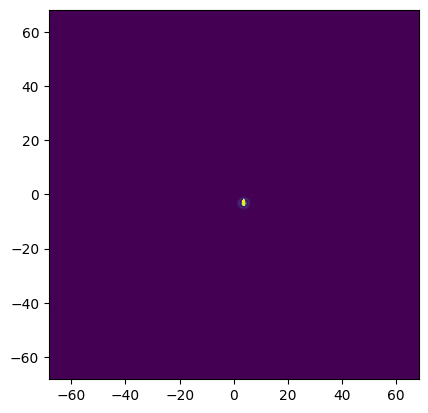

In [ ]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_m1offset.fits')

In [57]:
def moving_average(a, n=10):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+1*std) & (data > mean-1*std)) #the indicies of numbers we're NOT rejecting
    return data[indices]

def block_means(vector, block_size=50):
    vector = np.asarray(vector)
    n_blocks = int(np.ceil(len(vector) / block_size))
    means = [vector[i*block_size:(i+1)*block_size].mean() for i in range(n_blocks)]
    return np.array(means)

In [5]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

0.0013700422498262627


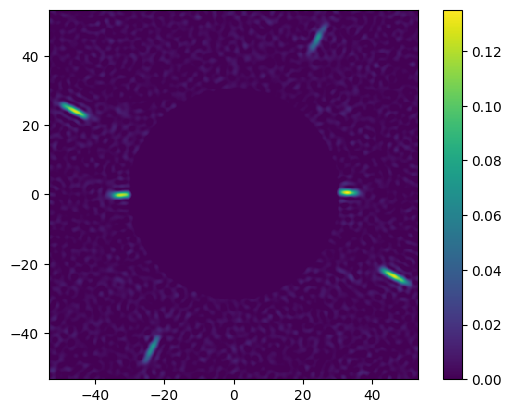

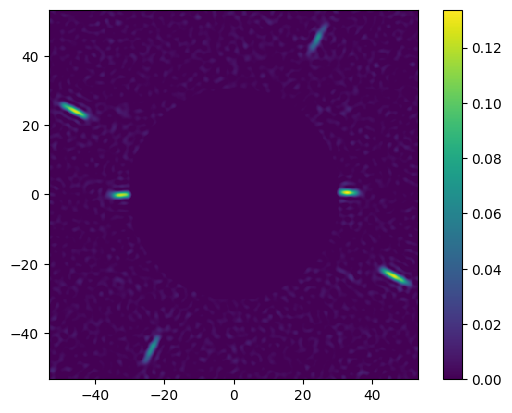

In [41]:
#function to get rid of background by thresholding
img = ADC.filter_image(ADC.crop_image(fieldcube[0]))
img[img < 0] = 0
bgd_avg = np.mean(img.shaped[20:40,20:40])
img_subtracted = img - bgd_avg
img_subtracted[img_subtracted < 0 ] = 0

imshow_field(img)
plt.colorbar()
plt.figure()
imshow_field(img_subtracted)
plt.colorbar()
print(bgd_avg)

In [49]:
disps = np.zeros(len(fieldcube))
commands = []
speckle_angles = []
pointings = []


for i, field in enumerate(fieldcube):
    filtered = ADC.filter_image(ADC.crop_image(field))
    ADC.set_psf(filtered)
    angles = ADC.find_speckle_angles2()
    pairs = ADC.speckle_pairs(angles)
    speckle_angles.append(angles)
    pointings.append(pairs)
    #commands.append(ADC.calculate_command(pairs))

pointings = np.array(pointings)
speckle_angles = np.array(speckle_angles)
#commands = np.array(commands)

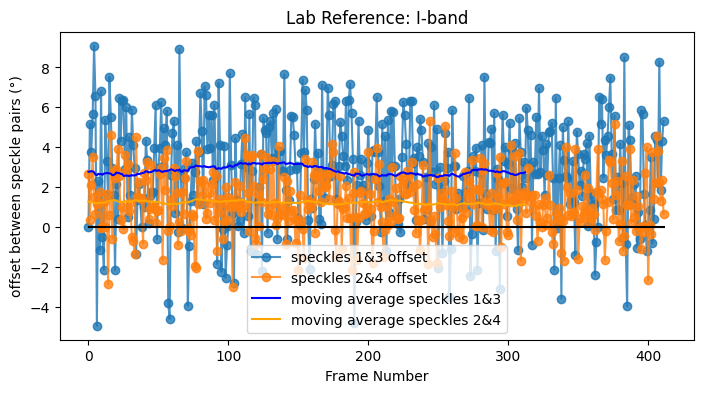

In [53]:
avg1 = moving_average((pointings[:,0]),n=100)
avg2 = moving_average((pointings[:,1]),n=100)

plt.figure(figsize=(18,4))
plt.subplot(1,2,1)
plt.plot((pointings[:,0]),'-o',label='speckles 1&3 offset',alpha=0.8)
plt.plot((pointings[:,1]),'-o',label='speckles 2&4 offset',alpha=0.8)
plt.plot(avg1,'-',label='moving average speckles 1&3',color='blue')
plt.plot(avg2,'-',label='moving average speckles 2&4',color='orange')
plt.hlines(0,0,len(pointings[:,0]),'black')
plt.xlabel('Frame Number')
plt.ylabel('offset between speckle pairs (°)')
plt.title('Lab Reference: I-band')
plt.legend()

In [58]:
point13 = pointings[:,0]
point24 = pointings[:,1]

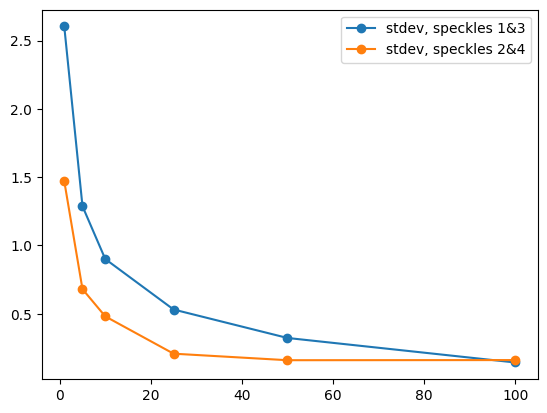

[2.60262059 1.28711276 0.90083451 0.53139966 0.32319977 0.14380571]
[1.47046545 0.68040312 0.48117385 0.20819994 0.16039106 0.16139319]


In [65]:
#looking at how averaging changes the variance
averages = np.array([1,5,10,25,50,100])
stds13 = np.zeros(len(averages))
stds24 = np.zeros(len(averages))

for i, average in enumerate(averages):
    means13 = block_means(point13, average)
    means24 = block_means(point24, average)
    stds13[i] = np.std(means13)
    stds24[i] = np.std(means24)

plt.plot(averages,stds13,'o-',label="stdev, speckles 1&3")
plt.plot(averages,stds24,'o-',label="stdev, speckles 2&4")
plt.legend()
plt.show()

print(stds13)
print(stds24)

In [ ]:
#write the speckle pair angles to .csv so you can just reference them in the future
np.savetxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/m1sat.csv',point13,delimiter=',')

In [ ]:
my_data = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/m1sat.csv',delimiter=',')

412
412
[-1.73628138e-02  5.17771015e+00  3.77815261e+00  5.65470560e+00
  9.09100514e+00  6.56736825e+00 -4.94411777e+00  2.30834371e+00
 -1.16886972e+00  6.81384689e+00 -5.07289533e-01 -2.12640171e+00
  5.38329214e+00  3.31722028e+00  1.60726860e+00  7.53365116e+00
  5.54226803e+00  2.95996213e+00  1.61382905e+00 -2.17066235e+00
  2.16823897e+00  4.04848428e-01  6.49440749e+00  4.29831554e+00
  6.31379771e+00  6.38534605e+00  2.92738786e+00  5.99874067e+00
  5.27156150e-01  4.50494101e+00  1.60075684e+00  5.89200155e+00
  4.11809346e+00  2.94764044e+00 -1.36826733e+00  1.36703427e+00
  2.18347037e+00  1.44554780e+00 -1.08491407e-04  1.42028731e+00
  9.83016682e-01  4.33970659e+00  3.35231739e+00  2.14435305e-01
  1.54632104e+00  1.75362895e+00  1.78144188e+00  3.96021551e+00
  6.10683537e+00 -6.00409283e-01  2.98522628e+00  3.96128075e+00
  6.25771072e+00  3.06017275e+00  4.94802712e+00  4.12695154e+00
  5.83384990e+00 -3.79604402e+00 -4.60015088e+00  2.59698231e+00
  4.69665863e+00 